# DSS: formulas learned by ASN, compared with the analytical solution

Actual training of the repository KAN/ASN · 18 October 2026

**The learned result is now separate from the analytical reference.** We trained the existing `nmrkan.models.KharKAN` implementation on numerically diagonalized DSS-type Hamiltonians, extracted its algebraic formulas, and evaluated them against the independent exact solution. The network never received the cubic formula, normal-mode energies, analytic derivatives, or a fitted one-dimensional cross-section as training inputs. It learned four ordered normalized eigenvalues from four normalized Hamiltonian parameters.

The manuscript calls this architecture an **activation-selection network (ASN)**. The repository class name is `KharKAN`; this experiment uses that class and its learned mixtures of zero, identity, and square functions. It is not a spline-edge KAN. The earlier [analytical report](dss_analysis.pdf) supplies the physical derivation and approximation audit; this report supplies the missing learned result and comparison.

## 1. Main DSS result

| Line | Exact / Hz | ASN / Hz | ASN error / mHz | Quadratic OLS / Hz |
|---|---:|---:|---:|---:|
| f12 | 3.708572427 | 3.708487082 | -0.085344 | 3.708863270 |
| f23 | 4.666648917 | 4.666514415 | -0.134502 | 4.666511051 |
| f13 | 8.375221344 | 8.375001497 | -0.219846 | 8.375374321 |


The selected local ASN has held-out frequency RMSE **0.002998667 Hz**, maximum held-out line error **0.04436489 Hz**, and a maximum line error at the supplied DSS point of **0.0002198465 Hz**. These errors measure approximation to the specified nearest-neighbor secular Hamiltonian; they are not experimental residuals. The predicted spectral positions are therefore usable within the demonstrated domain, subject to the separate physical approximations documented in the analytical report.

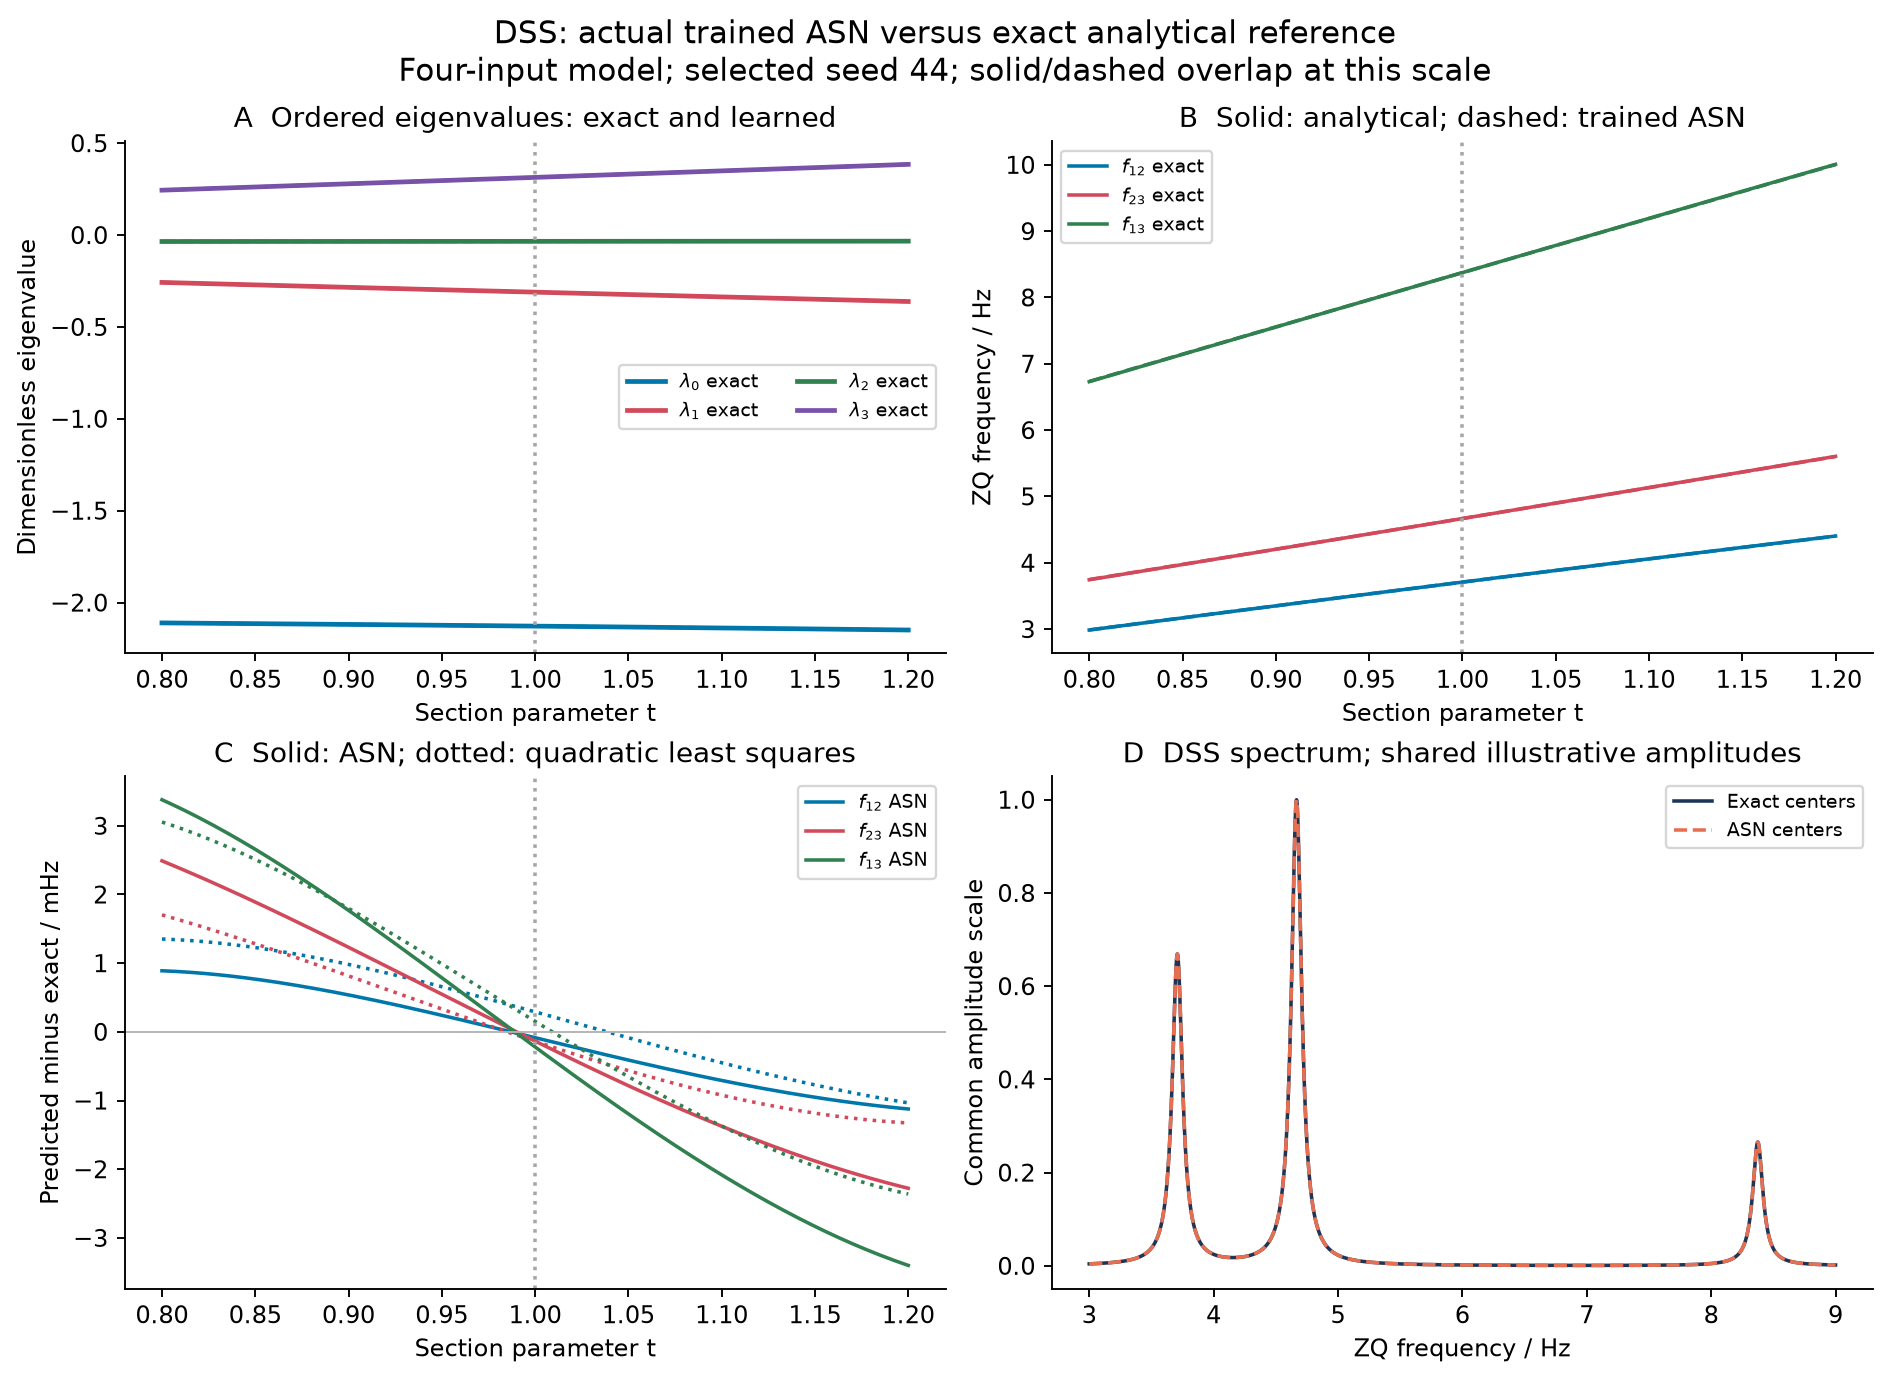

## 2. Training design and correspondence to the manuscript

We used the full four-state matrix, including type-II mixing, with $q=0$. Targets were generated by `numpy.linalg.eigvalsh` of the physical Hamiltonian, ordered from lowest to highest, then transformed as $\lambda_i=(E_i-E_{\rm ref})/s$. The four inputs are

$$s=-J_M,\quad x_A=(J_A-J_M)/s,\quad x_X=(J_X-J_M)/s,\quad u=d/s,\quad v=e/s.$$

All four energies are learned jointly. No positive-energy filtering, post-prediction sorting, symmetry averaging, or trace projection is applied. Frequency predictions use fixed target indices:

$$\widehat E_i=E_{\rm ref}+s\widehat\lambda_i,\qquad
\widehat f_{12}=s(\widehat\lambda_2-\widehat\lambda_1),\quad
\widehat f_{23}=s(\widehat\lambda_3-\widehat\lambda_2),\quad
\widehat f_{13}=\widehat f_{12}+\widehat f_{23}.$$

Two parameter domains were specified before evaluating the test data. The **DSS local domain** independently varies each supplied geminal coupling by ±0.3 Hz and each nearest-neighbor difference by ±20%. It is a numerical approximation domain, not a fitted uncertainty interval. The **broad domain** is the original supplied box: three geminals in [−15,−12.5] Hz and both differences in [0.1,7] Hz. The local e range extends to 7.9166604 Hz, so these two domains are deliberately different; their errors are not compared as if measured on identical populations.

Within each domain, 100,000 physical parameter vectors were sampled using NumPy seed 42, then divided into **80,000 training, 10,000 validation, and 10,000 test samples** with disjoint indices. Model initialization and minibatch-order seeds were 42, 43, 44, 45, and 46. The exact supplied DSS point and the displayed continuous section were not inserted into the training set.

The architecture is **(4,16,4)** with biases and activation library **{0,x,x²}**. This directly extends the manuscript's (2,16,4) network to four inputs. Training used Adam, learning rate 0.001, batch size 4096, 1000 epochs, and MAE. For epochs 1–900, softmax activation weights and a 0.1×L0.5 regularizer were used; epochs 901–1000 used sparsemax without that regularizer. Each seed's checkpoint and the representative seed were selected only by validation RMSE in dimensionless eigenvalues during the sparsemax phase. Test data were evaluated after this selection.

One additional numerical-conditioning step differs from the original manuscript experiment: inputs and normalized outputs were centered and divided by their **training-set** standard deviations. MAE was applied to these standardized outputs. Both affine transforms were algebraically undone during extraction, so the delivered formulas are functions of $(x_A,x_X,u,v)$ and return $\lambda_i$ in the stated physical normalization. This is a new DSS experiment, not a claim to reproduce the paper's older training run bit for bit.

The selected local model uses seed **44**, checkpoint epoch **901**. Its activation choices are **layer 1: identity=4, square=0, zero=0; layer 2: identity=10, square=5, zero=1**. The selected model's extracted polynomial degrees are **[2, 2, 2, 2]**. Sparsemax support sizes, weights, optimizer settings, data hashes, model-source hash, versions, full training curves, and every checkpoint are retained in `asn_comparison/`.

## 3. The actual learned formulas

The files `asn_comparison/local/learned_formulas.json` and `.tex` contain the full four-input formulas obtained by composing the trained layers. They are not a least-squares fit substituted for the network. Evaluation of the extracted formulas agrees with the trained network to **3.55e-15 dimensionless units** on 1000 validation points. An independent test reloads the saved checkpoint and checks this equivalence on held-out inputs.

For the paper-style representation, coefficients with magnitude below 0.001 were removed and remaining coefficients rounded to three decimals, following the supplied manuscript's extraction procedure. Unequal geminals do not permit the manuscript's uniform-chain symmetry averaging, so that operation was not applied. The table below defines $\widehat\lambda_i=\sum_m c_{im}m(x_A,x_X,u,v)$ for the **rounded local model**. Full-precision and rounded errors are reported separately.

| Monomial | λ0 | λ1 | λ2 | λ3 |
|---|---:|---:|---:|---:|
| $1$ | -1.999 | 0.000 | 0.000 | -0.001 |
| $v$ | -0.006 | -0.399 | 0.024 | 0.382 |
| $u$ | 0.000 | -0.307 | -0.029 | 0.337 |
| $x_X$ | 1.016 | 0.332 | 0.388 | 0.262 |
| $x_A$ | 1.009 | 0.183 | 0.607 | 0.201 |
| $v^{2}$ | -0.113 | -0.203 | 0.187 | 0.130 |
| $u v$ | -0.010 | 0.640 | -0.410 | -0.221 |
| $u^{2}$ | -0.119 | -0.300 | 0.236 | 0.185 |
| $v x_X$ | -0.054 | 0.580 | -0.951 | 0.426 |
| $u x_X$ | -0.007 | -0.800 | 1.209 | -0.401 |
| $x_X^{2}$ | 0.008 | -0.605 | 0.150 | 0.445 |
| $v x_A$ | 0.001 | -0.573 | 0.937 | -0.367 |
| $u x_A$ | -0.053 | 0.696 | -1.180 | 0.536 |
| $x_A x_X$ | -0.011 | 0.583 | -0.097 | -0.478 |
| $x_A^{2}$ | -0.025 | -0.383 | -0.054 | 0.460 |


These are learned coefficients. The exact analytical cubic has a different role: it is a physics reference used to assess the approximation. Ordinary least squares below is another distinct model trained on the same data; it is never labeled ASN.

## 4. Analytical and learned expressions on the same cross-section

Fix the DSS geminals and use

$$d(t)=5.269170t,\qquad e(t)=6.597217t\quad\mathrm{Hz}.$$

The exact analytical construction uses the squared normal-mode roots of

$$z^3-C_1(t)z^2+C_2(t)z-C_3(t)=0,$$

$$C_1(t)=3.162281774033+0.396528696796t^2,$$
$$C_2(t)=3.330354094093+0.426234440375t^2+0.037387752092t^4,\quad C_3(t)=1.168072320061.$$

For ordered roots $z_1\le z_2\le z_3$, define $\omega_i=s\sqrt{z_i}$. Then

$$f_{12}=\omega_3-\omega_2,\quad f_{23}=\omega_2-\omega_1,\quad f_{13}=\omega_3-\omega_1.$$

The **learned** expressions below are obtained solely by substituting this section into the trained four-input ASN formulas and taking their differences. No additional fitting along t was performed. Displayed coefficients are rounded to nine decimals; the stored coefficients retain numerical precision.

$$\widehat f_{12}(t)=- 0.345905233 t^{2} + 4.228476871 t - 0.174084556\quad\mathrm{Hz}.$$

$$\widehat f_{23}(t)=0.197857469 t^{2} + 4.24262703 t + 0.226029917\quad\mathrm{Hz}.$$

$$\widehat f_{13}(t)=- 0.148047765 t^{2} + 8.471103901 t + 0.051945361\quad\mathrm{Hz}.$$

These learned expressions are finite-domain approximations. Their range of support from the local training domain is $0.8\le t\le1.2$. On the 161-point sampled section within that interval, the learned frequency RMSE is **0.001532661 Hz** and maximum error is **0.003400095 Hz**. Results outside this interval are explicitly treated as extrapolation.

For a direct comparison with the analytical local description, expand about $\delta=t-1$. The columns below give the constant, linear, and quadratic coefficients in Hz. Analytical coefficients come from differentiating the exact Hamiltonian solution. Learned coefficients come from differentiating the extracted ASN polynomial; they were not imposed during training.

| Line | Exact value | Learned value | Exact slope | Learned slope | Exact quadratic coefficient | Learned quadratic coefficient |
|---|---:|---:|---:|---:|---:|---:|
| f12 | 3.708572 | 3.708487 | 3.543283 | 3.536666 | -0.346209 | -0.345905 |
| f23 | 4.666649 | 4.666514 | 4.651738 | 4.638342 | 0.191450 | 0.197857 |
| f13 | 8.375221 | 8.375001 | 8.195021 | 8.175008 | -0.154759 | -0.148048 |


Agreement in values need not imply equally accurate derivatives or curvatures. Unlike the exact Taylor series, the learned polynomial is optimized over a finite four-dimensional sample distribution. It must not be described as rediscovering perturbative coefficients merely because its polynomial degree matches.

## 5. Held-out comparisons and seed variability

All methods within a domain use the same 80,000 training vectors and 10,000 held-out test vectors. The fixed-basis fits use complete degree-2 (15 monomials) and degree-4 (70 monomials) polynomial bases in the same affinely conditioned inputs, and ordinary least squares. Degree 2 is the natural matched polynomial baseline when the learned ASN reduces to a quadratic; degree 4 tests additional polynomial capacity. Least squares minimizes squared error, whereas ASN training uses MAE plus activation regularization. The physics references do not fit training data.

**DSS local domain**

| Method | Eigenvalue RMSE / Hz | Frequency RMSE / Hz | Max. line error / Hz | Ordering violations |
|---|---:|---:|---:|---:|
| Exact analytical cubic | 5.0313e-15 | 5.91571e-15 | 2.66454e-14 | 0 |
| ASN | 0.00151679 | 0.00299867 | 0.0443649 | 0 |
| ASN paper-style 3-decimal rounding | 0.00721902 | 0.00794475 | 0.046856 | 0 |
| OLS degree 2 | 0.00139327 | 0.00278564 | 0.0376895 | 0 |
| OLS degree 4 | 3.85023e-05 | 7.70047e-05 | 0.00192845 | 0 |
| Effective 3x3 | — | 0.0063361 | 0.0185842 | — |
| Bare 3x3 | — | 0.228743 | 0.483789 | — |


**Broad supplied domain**

| Method | Eigenvalue RMSE / Hz | Frequency RMSE / Hz | Max. line error / Hz | Ordering violations |
|---|---:|---:|---:|---:|
| Exact analytical cubic | 5.3134e-15 | 6.71216e-15 | 4.30767e-14 | 0 |
| ASN | 0.0725538 | 0.144956 | 1.92457 | 4 |
| ASN paper-style 3-decimal rounding | 0.0725919 | 0.145038 | 1.91998 | 4 |
| OLS degree 2 | 0.0703782 | 0.140741 | 1.72007 | 1 |
| OLS degree 4 | 0.0288095 | 0.0576189 | 0.711797 | 0 |
| Effective 3x3 | — | 0.00273032 | 0.020747 | — |
| Bare 3x3 | — | 0.142218 | 0.55397 | — |


For the selected broad model, the DSS-point predicted frequencies are **3.704907, 4.642163, 8.347070 Hz**. Its broader-domain performance must not be conflated with the local model's accuracy. Separate checkpoint files and reports identify which domain produced each prediction.

Five-seed frequency-RMSE means ± sample standard deviations are **0.00357974 ± 0.000860124 Hz** locally and **0.146665 ± 0.00310612 Hz** broadly. These statistics measure optimization variability on fixed data, not experimental uncertainty or generalization over independently regenerated datasets.

| Domain | Seed | Best epoch | Validation eigenvalue RMSE (dimensionless) | Test frequency RMSE / Hz |
|---|---:|---:|---:|---:|
| local | 42 | 1000 | 0.0002903371 | 0.005020475 |
| local | 43 | 951 | 0.0001148422 | 0.003027516 |
| local | 44 (selected) | 901 | 0.0001143823 | 0.002998667 |
| local | 45 | 1000 | 0.000134696 | 0.003114833 |
| local | 46 | 981 | 0.0002242032 | 0.003737206 |
| broad | 42 | 981 | 0.005932914 | 0.1520699 |
| broad | 43 | 941 | 0.005397352 | 0.1449643 |
| broad | 44 | 921 | 0.005461121 | 0.1465545 |
| broad | 45 (selected) | 931 | 0.005391291 | 0.1449562 |
| broad | 46 | 971 | 0.005394605 | 0.1447796 |


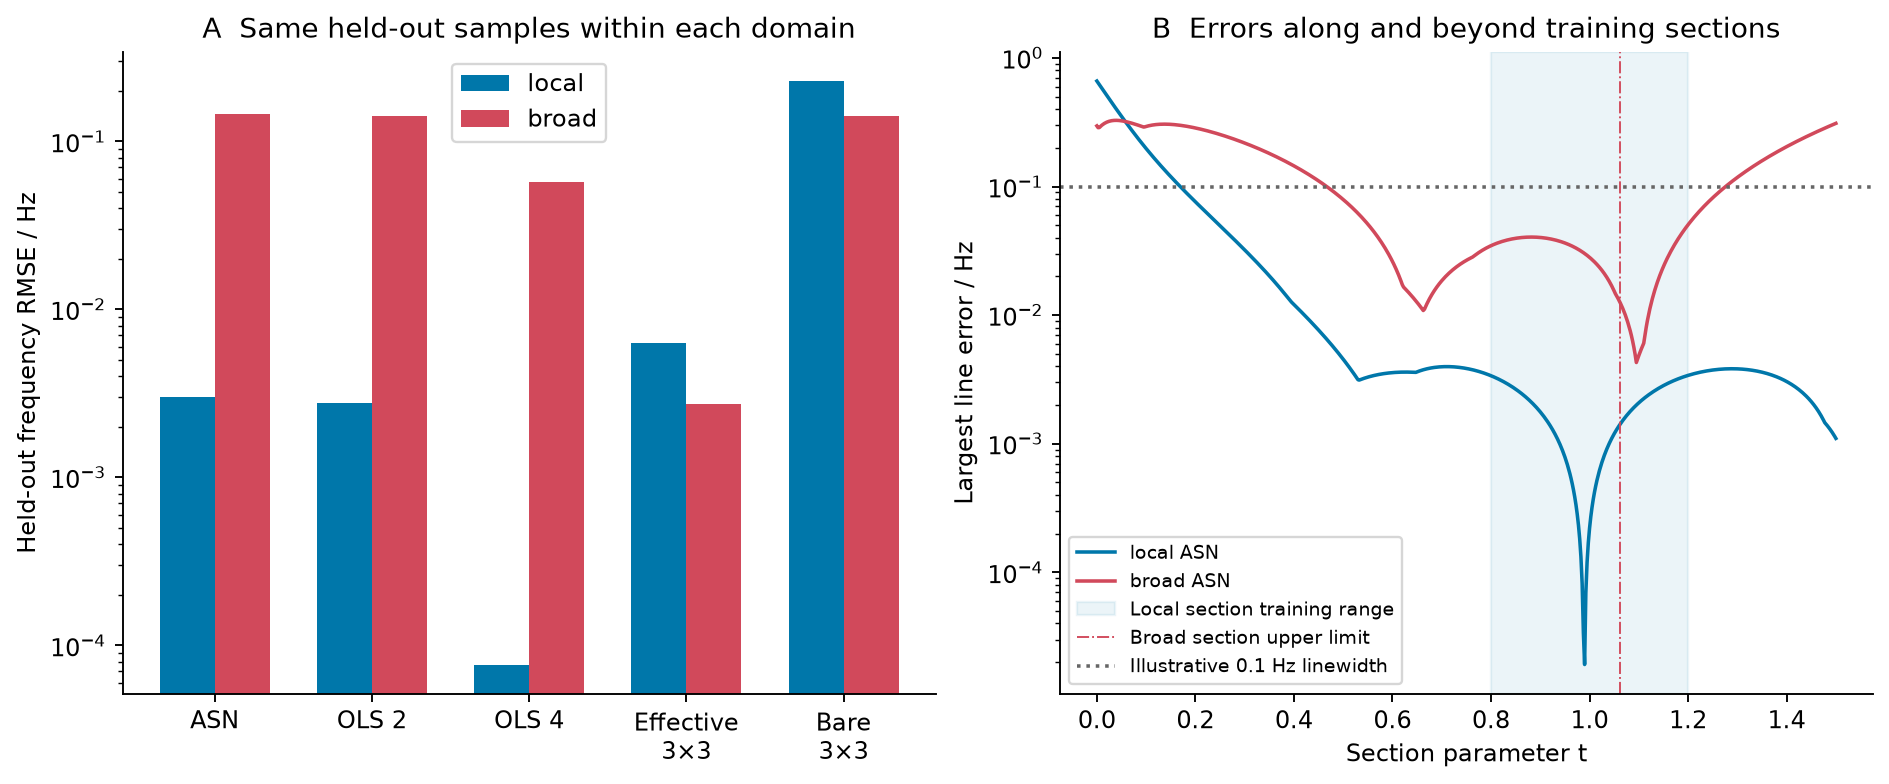

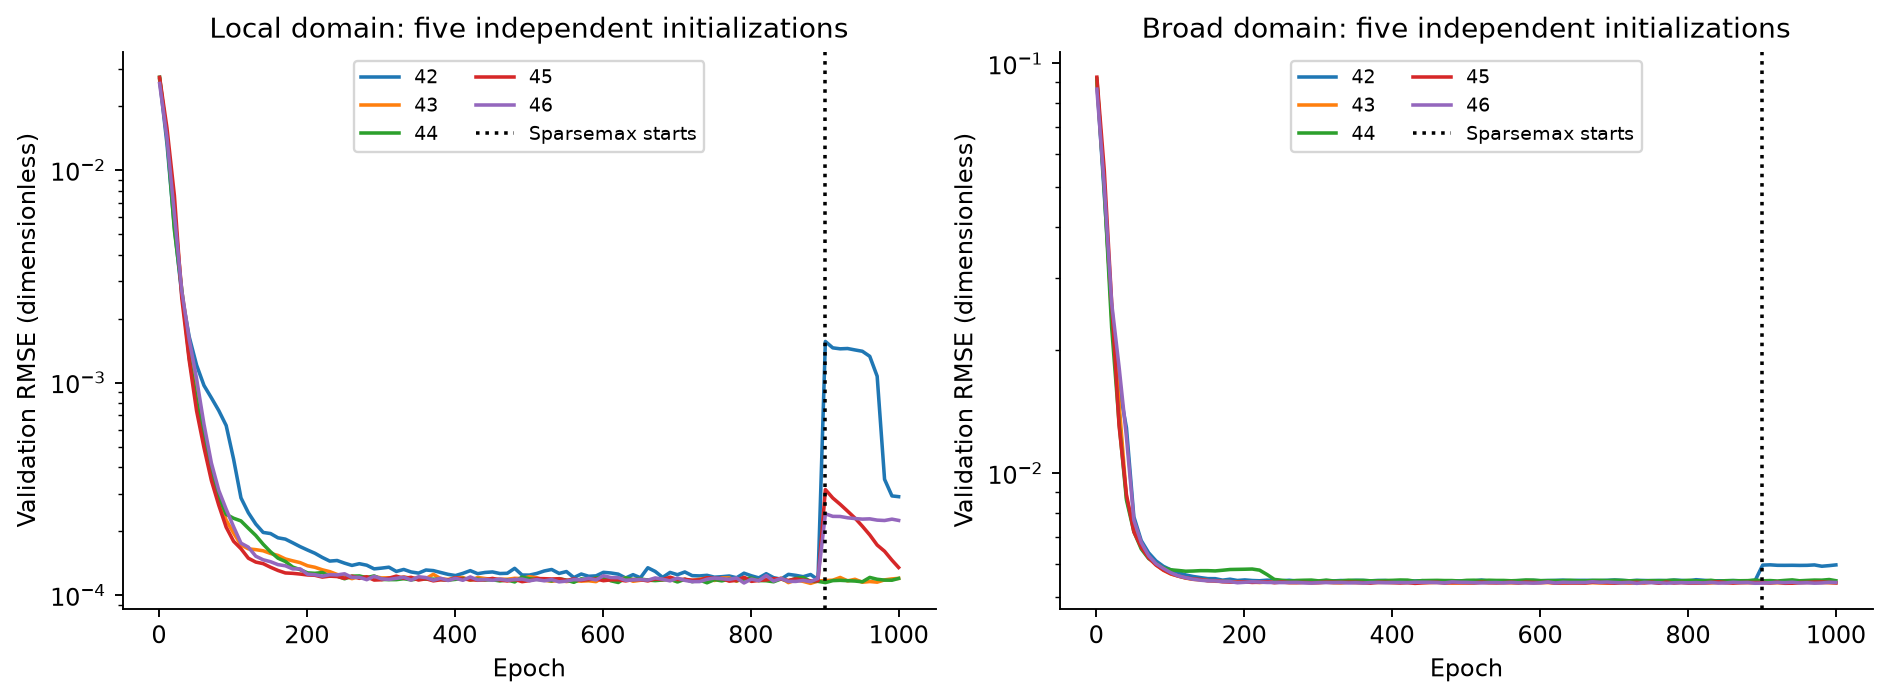

## 6. Ordering, rounding, and observability

The training labels use the manuscript's ordered physical-energy convention. The exact solution's degeneracies and boundary cusps remain a challenge for a global polynomial approximation. We count negative adjacent predicted energy differences before any correction. The selected local and broad models have **0** and **4** ordering violations, respectively, on their 10,000-point in-domain test sets.

A separate 2000-point decoupled-boundary challenge sets d=0 or e=0 with broad-box geminals. It is outside the local model's domain and on the closure of the broad model's domain. Local and broad maximum line errors there are **2.81877 Hz** and **2.00535 Hz**, with **259** and **52** ordering violations. These tests expose limitations; the analysis does not sort the predictions afterward to hide swaps. Neither test accuracy nor zero sampled violations is a mathematical global ordering guarantee.

The gap identity $\widehat f_{13}=\widehat f_{12}+\widehat f_{23}$ holds by construction, but no trace constraint was imposed on the four learned energies. Trace errors are recorded in the JSON metrics. The paper-style rounded local formulas predict DSS frequencies **3.711624, 4.673886, 8.385510 Hz**; their distinct error row quantifies information lost during symbolic presentation.

For the spectral overlay, both predictions use the same illustrative local-singlet autocorrelation amplitudes and a Lorentzian FWHM of 0.1 Hz. **Only the line centers are replaced by the ASN predictions.** This isolates the consequence of learned eigenvalue errors. The ASN does not predict eigenvectors, preparation efficiencies, relaxation, or experimental line intensities. The underlying molecular approximation retains type-II mixing and three unequal geminals; omitted fitted q still causes approximately 0.002 Hz line shifts at DSS, independently of surrogate error.

## 7. How this fits the paper's narrative

The physical example now has the required sequence: a real molecule supplies couplings; numerical diagonalization supplies supervised targets; dimensionless normalization reduces five physical parameters to four inputs; the ASN learns a sparse polynomial representation; algebraic extraction produces explicit four-input and cross-section formulas; and the predicted energy differences are compared with an exact analytical reference in spectral units.

The evidence supports **useful explicit learned approximations in a stated molecular domain**. It does not establish an accuracy advantage over a suitable polynomial basis or the exact cubic solver. The least-squares results must remain in the paper, including any cases where they outperform ASN. This is consistent with the manuscript's existing conclusion that activation selection does not intrinsically beat an appropriate predefined basis.

The broad-domain experiment and boundary checks make the limitation visible: a compact polynomial cannot generally reproduce every cusp of ordered eigenvalue surfaces. The local DSS demonstration should therefore be presented as a controlled molecular application, not a universal analytical solution. The exact result is the reference; the ASN result is the learned approximation. Training over a wider domain, using richer primitives, or adding constraints would be new experiments rather than corrections silently applied to these results.

The editor's separate request for comparisons with contemporary symbolic-regression methods still calls for a justified external baseline such as PySR/EQL and a common budget protocol. The current work runs ASN and fixed-basis baselines, not those external methods. Literature context and the experimental provenance limits remain documented in the analytical report. No experimental residuals or measured intensities have been invented.

## 8. Reproducibility and manuscript material

- `train_dss_asn.py` performs the actual training, saves all five seeds in each domain, and extracts the selected network.
- `asn_comparison/{local,broad}/dataset.npz` stores physical parameters, normalized inputs, ordered targets, and disjoint split indices.
- `config.json`, `training_summaries.json`, `history_seed_*.csv`, and `seed_*.pt` retain the complete experiment configuration and model artifacts.
- `learned_formulas.json`, `learned_formulas.tex`, and `paper_rounded_formulas.tex` distinguish full-precision extraction from paper-style rounding.
- `comparison.json`, `postprocessing.json`, `heldout_predictions.npz`, and `cross_section_comparison.csv` contain the numerical comparisons.
- `asn_comparison/dss_manuscript_addition.tex` is a draft manuscript insert with actual measured benchmark values.
- `test_dss_asn.py` checks target construction, disjoint splits, unmodified branch labels, checkpoint reloads, symbolic extraction, validation-based selection, and reproducibility of saved test metrics.

From the repository root, in an environment containing the repository dependencies plus the report dependencies:

```bash
python ANSWER/train_dss_asn.py --domain local
python ANSWER/train_dss_asn.py --domain broad
python ANSWER/build_asn_comparison_report.py
python -m unittest discover -s ANSWER -p 'test*.py' -v
```

The CPU training runs used PyTorch 2.14.1+cpu with one computation thread per process. No repository model source was changed. The temporary execution environment is `/tmp/nmrkan-analysis-venv`. The HTML embeds its figures and uses native MathML; the notebook retains editable equations and links to the saved artifacts.

In [ ]:
from pathlib import Path
import json, sympy as sp, numpy as np
root = Path.cwd() if (Path.cwd()/'asn_comparison').exists() else Path.cwd()/'ANSWER'
f = json.loads((root/'asn_comparison/local/learned_formulas.json').read_text())
symbols=sp.symbols('xA xX u v')
expressions=[sp.sympify(e) for e in f['formulas']]
for i,e in enumerate(expressions):
    print('lambda',i,'=',e)
